# CRISP-ML(Q) Phase 1 – Business and Data Understanding

**Project:** Arbovirus differential diagnosis with explainable AI – a "smart hospital" module for the first consultation
of a febrile patient.

The project follows **CRISP-ML(Q)** (*CRoss-Industry Standard Process for the development of Machine Learning applications
with Quality assurance methodology*, Studer et al., 2021). It adapts CRISP-DM to machine learning: business and data
understanding are one phase, because whether the data can support the goal decides whether the project is feasible, and it
adds a final phase to **monitor and maintain** the model once deployed. Every phase also identifies its **risks** and how
to check them (the "Q" for quality assurance). Each phase has a notebook and a page in the web app:

| # | CRISP-ML(Q) phase | Notebook | Web page |
|---|---|---|---|
| 1 | Business and Data Understanding | `01_business_and_data_understanding.ipynb` | `/methodology/1` |
| 2 | Data Engineering | `02_data_engineering.ipynb` | `/methodology/2` |
| 3 | Machine Learning Model Engineering | `03_model_engineering.ipynb` | `/methodology/3` |
| 4 | Quality Assurance for ML Applications | `04_quality_assurance.ipynb` | `/methodology/4` |
| 5 | Deployment | `05_deployment.ipynb` | `/methodology/5` |
| 6 | Monitoring and Maintenance | `06_monitoring_maintenance.ipynb` | `/methodology/6` |

The process is **iterative**: results of later phases send the work back to earlier ones.

This notebook has two parts: **business understanding** (1.1–1.7) and **data understanding** (1.8–1.12). No model is trained
in this phase.

## 1.1 Problem

Dengue, chikungunya and Zika are transmitted by the same mosquito (*Aedes aegypti*), co-circulate in Colombia and Brazil
and begin with almost the same picture: fever, headache, muscle and joint pain, rash. At the first consultation the clinician
must decide **what to suspect, which test to order and how to follow the patient**. Errors matter:

- Dengue can progress to **severe dengue**; its warning signs must be watched.
- The anti-inflammatory drugs (NSAIDs) used for chikungunya's joint pain **are dangerous in dengue**.

## 1.2 How the objective evolved (CRISP-ML(Q) is a cycle)

| Iteration | Objective | Outcome |
|---|---|---|
| 0 | Forecast weekly dengue cases | Kept as the baseline forecast on the home page |
| 1 | Binary screening: *dengue yes/no* (SIVIGILA Tuluá, Colombia) | Worked (ROC-AUC ≈ 0.63) but judged **too narrow** |
| **2 (current)** | **Differential diagnosis among arboviruses + explanations** | This version |

## 1.3 Business objective

Support the clinician at the first consultation of a febrile patient: which arbovirus to suspect, which test to order and
which warning signs to watch, **with a transparent explanation** of the suggestion.

> ⚠️ Clinical **decision support**, not a diagnosis. Confirmation is always clinical and by laboratory.

## 1.4 Data-mining objective

A **multiclass classifier**: `dengue` / `chikungunya` / `other_febrile`, from information available at the first
consultation — age, sex, days since onset, symptoms, basic clinical and laboratory findings, comorbidities and the
**epidemiological context** (state of residence and month: local circulation) — plus **SHAP explanations** for every
prediction. Target set by the course: macro ROC-AUC **above 0.80**.

Candidate algorithms (well suited to tabular clinical data): **Random Forest, XGBoost and LightGBM**, compared against a
linear baseline (Logistic Regression).

## 1.5 Success criteria (fixed before modeling)

| Criterion | Target | Why |
|---|---|---|
| Dengue recall | **≥ 80 %** | Missing dengue is the most dangerous error |
| Macro ROC-AUC (one-vs-rest) | **≥ 0.80** | Rank the three diagnoses well (target set by the course) |
| Better than the linear baseline | yes | Justifies the complexity of tree ensembles |
| Explainability | every prediction | A clinician must see *why* |
| Data leakage | none | Only information available at the first consultation |

## 1.6 Resources, constraints and risks

| Item | Detail |
|---|---|
| Data | SINAN (Brazil, DATASUS) for training; SIVIGILA Tuluá (Colombia) for external validation |
| Tools | Python, pandas, scikit-learn, XGBoost, LightGBM, SHAP, Flask, SQLAlchemy, Render |
| Constraint | No public dataset has **numeric** lab values (platelet or white-cell counts) |
| Constraint | Zika's public notification form has **no clinical fields** |
| Risk | Overlapping symptoms limit how well any model can separate the diseases |
| Risk | A model trained in Brazil may not transfer to Colombia → external validation |
| Ethics | Decision support only, visible notice, transparent explanations |

## 1.7 Project plan

| Phase | Main output | Code |
|---|---|---|
| 1. Business and Data Understanding | Objectives, source inventory, label quality, clinical signal | `src/dbc.py`, `src/sinan.py` |
| 2. Data Engineering | Lab-confirmed, class-balanced datasets 2023 and 2025 | `src/sinan.py`, `src/preprocessing.py` |
| 3. Model Engineering | Four models compared, dengue alert threshold | `src/train.py` |
| 4. Quality Assurance | Test, SHAP, temporal (2025) and external (Colombia) validation | `src/train.py`, `src/explain.py` |
| 5. Deployment | Web app with per-patient explanations | `app.py`, `src/prediction.py` |
| 6. Monitoring and Maintenance | Drift report and retraining rules | `src/monitoring.py` |


## Part 2 – Data understanding

**Goal:** find data that can teach a model to tell arboviruses apart, and understand its structure and quality.
**No model is trained in this phase.**

## 1.8 Searching for sources

| Source | Diseases | Symptoms | Lab | Decision |
|---|---|---|---|---|
| SIVIGILA Tuluá, Colombia (datos.gov.co `dq2k-gub9`) | Dengue only (confirmed vs discarded) | Yes | Yes/no | External validation |
| Medellín Zika (`v6vb-p4sp`) and Chikungunya (`nu5z-zutz`) | Zika, chikungunya | **No** (age, sex, neighborhood) | No | Not usable |
| **SINAN, Brazil (DATASUS FTP)** | Dengue + chikungunya (same form); Zika (short form) | Yes | Yes/no | **Training** |

SINAN publishes one file per disease and year (`DENGBR23.dbc`, `CHIKBR23.dbc`, `ZIKABR23.dbc`…). The `.dbc` format is a
compressed dBase table; the usual readers need a C compiler, so the project includes its own pure-Python reader,
`src/dbc.py`. Downloading and reading is done by `python -m src.sinan` (several minutes; ~3.8 million records), which also
stores the raw counts used below in `data/processed/arbovirus_<year>_summary.json`.

In [1]:
import sys
sys.path.insert(0, "..")  # project root, to import the src package

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

from src.preprocessing import BINARY, CLASS_LABELS, CLASSES, FEATURE_LABELS, SINAN_COLUMNS
from src.sinan import TRAIN_YEAR, load_dataset

summary = json.loads(open(f"../data/processed/arbovirus_{TRAIN_YEAR}_summary.json", encoding="utf-8").read())
for f in summary["files"]:
    print(f"{f['source']}: {f['records']:,} records")

DENGBR23: 1,645,956 records
CHIKBR23: 266,442 records


## 1.9 How were the cases classified?

`CLASSI_FIN` (final classification): 5 = discarded, 8 = inconclusive, 10 = dengue, 11 = dengue with warning signs,
12 = severe dengue, 13 = chikungunya. `CRITERIO` (how it was closed): 1 = **laboratory**, 2 = clinical-epidemiological,
3 = under investigation.

In [2]:
for f in summary["files"]:
    table = pd.DataFrame(f["classification_by_criterion"]).T.fillna(0).astype(int)
    print(f"\n=== {f['source']} (rows = CLASSI_FIN, columns = CRITERIO)")
    display(table)


=== DENGBR23 (rows = CLASSI_FIN, columns = CRITERIO)


,0,1,2,3,blank
0,2166,26,14,5906,0
10,733,638301,754849,7536,0
11,17,14451,8624,576,0
12,2,1293,335,56,0
8,0,1032,2304,8015,196336
blank,0,4,5,227,3148



=== CHIKBR23 (rows = CLASSI_FIN, columns = CRITERIO)


,0,1,2,3,blank
0,275,2,3,105,0
13,4,56197,72411,1584,0
5,29,58353,49577,85,0
blank,0,32,57,1969,25759


**Reading:**
- About half of the cases are closed by the **clinical-epidemiological** criterion, i.e. from the symptoms themselves. Using
  them would be circular: the model would learn the doctor's rule, not the disease. → **Only laboratory-closed cases.**
- The public **dengue** file contains **no discarded cases** (no `CLASSI_FIN = 5`): Brazil publishes only probable dengue.
  Discarded cases exist only among chikungunya suspects. → The "other febrile illness" class is
  **chikungunya suspects ruled out by the laboratory**. This is a limitation: dengue was not formally excluded for them.

## 1.10 Why Zika cannot be modeled

In [3]:
zika_columns = summary["zika_columns"]
print(len(zika_columns), "columns in the Zika file:")
print(zika_columns)
print("\nClinical fields present:", [c for c in SINAN_COLUMNS.values() if c in zika_columns] or "none")

38 columns in the Zika file:
['TP_NOT', 'ID_AGRAVO', 'DT_NOTIFIC', 'SEM_NOT', 'NU_ANO', 'SG_UF_NOT', 'ID_MUNICIP', 'ID_REGIONA', 'ID_UNIDADE', 'DT_SIN_PRI', 'SEM_PRI', 'ANO_NASC', 'NU_IDADE_N', 'CS_SEXO', 'CS_GESTANT', 'CS_RACA', 'CS_ESCOL_N', 'SG_UF', 'ID_MN_RESI', 'ID_RG_RESI', 'ID_PAIS', 'NDUPLIC_N', 'IN_VINCULA', 'DT_INVEST', 'ID_OCUPA_N', 'CLASSI_FIN', 'CRITERIO', 'TPAUTOCTO', 'COUFINF', 'COPAISINF', 'COMUNINF', 'DOENCA_TRA', 'EVOLUCAO', 'DT_OBITO', 'DT_ENCERRA', 'DT_DIGITA', 'TP_SISTEMA', 'TPUNINOT']

Clinical fields present: none


## 1.11 Clinical signal by disease

The processed sample of laboratory-confirmed cases (built in Phase 2) is used to see whether symptoms differ between diseases.

In [4]:
X, y, context = load_dataset(TRAIN_YEAR)
data = X.assign(diagnosis=y.map(dict(enumerate(CLASSES))))
print(data["diagnosis"].value_counts())
print("\nMissing values per feature (%):")
print((X.isna().mean() * 100).round(2).loc[lambda s: s > 0])

diagnosis
dengue           40000
chikungunya      40000
other_febrile    40000
Name: count, dtype: int64

Missing values per feature (%):
days_since_onset    3.52
dtype: float64


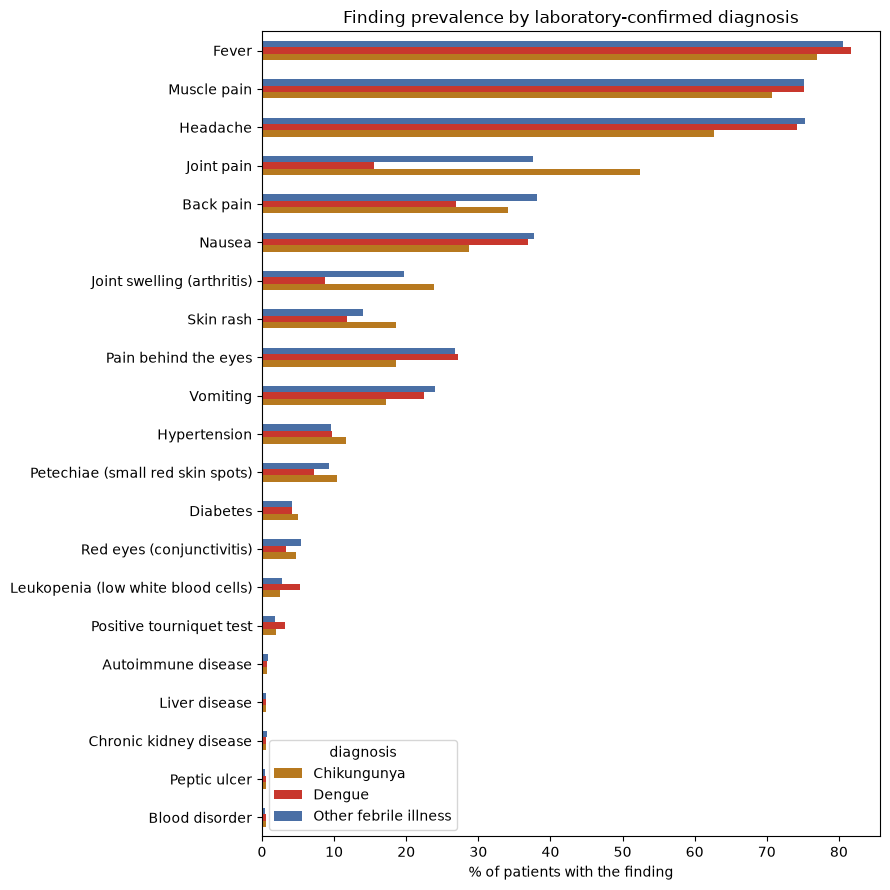

diagnosis,Chikungunya,Dengue,Other febrile illness
Fever,76.9,81.6,80.6
Headache,62.6,74.2,75.3
Pain behind the eyes,18.6,27.1,26.8
Muscle pain,70.7,75.2,75.2
Joint pain,52.4,15.5,37.5
Joint swelling (arthritis),23.8,8.8,19.7
Back pain,34.2,26.9,38.1
Skin rash,18.6,11.8,14.0
Red eyes (conjunctivitis),4.8,3.3,5.4
Nausea,28.6,36.8,37.7


In [5]:
prevalence = (data.groupby("diagnosis")[BINARY].mean() * 100).T.rename(index=FEATURE_LABELS, columns=CLASS_LABELS)
ax = prevalence.sort_values("Chikungunya").plot.barh(figsize=(9, 9), color=["#b7791f", "#c8372d", "#4a6fa5"])
ax.set_xlabel("% of patients with the finding"); ax.set_title("Finding prevalence by laboratory-confirmed diagnosis")
plt.tight_layout(); plt.show()
prevalence.round(1)

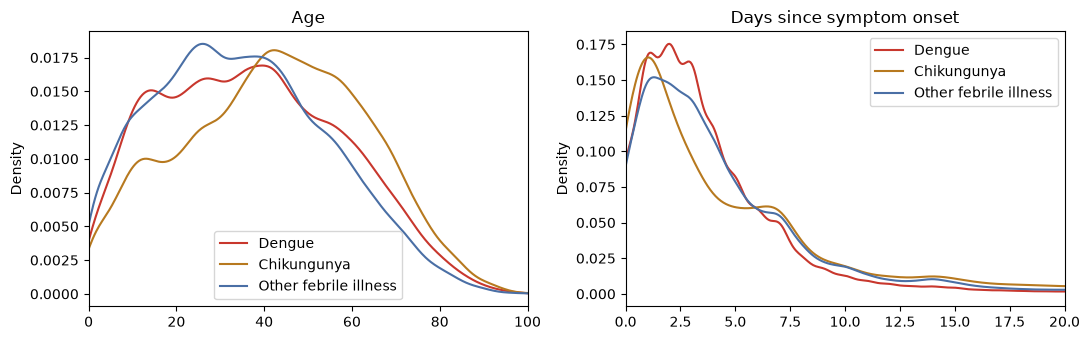

diagnosis      state
chikungunya    31       0.561
               29       0.100
               17       0.044
dengue         35       0.305
               31       0.163
               42       0.120
other_febrile  31       0.208
               50       0.176
               35       0.088
Name: proportion, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, col in zip(axes, ["age", "days_since_onset"]):
    for c, color in zip(CLASSES, ["#c8372d", "#b7791f", "#4a6fa5"]):
        data.loc[data["diagnosis"] == c, col].plot.kde(ax=ax, label=CLASS_LABELS[c], color=color)
    ax.set_title(FEATURE_LABELS[col]); ax.set_xlim(0, 100 if col == "age" else 20); ax.legend()
plt.tight_layout(); plt.show()
print(context.assign(diagnosis=data["diagnosis"]).groupby("diagnosis")["state"].value_counts(normalize=True)
      .groupby(level=0).head(3).round(3))

## 1.12 Phase conclusions

- **Joint pain (arthralgia) and arthritis** are much more frequent in chikungunya; **leukopenia**, **retro-orbital pain** and
  **headache** lean toward dengue. Symptoms carry information, but the distributions overlap a lot → expect a useful but
  imperfect model.
- **No missing values** in symptoms, and no difference in missingness between classes → no leakage from data quality.
- **Numeric lab values** (`PLAQ_MENOR`, lowest platelet count) are empty in 100 % of records: lab information enters only as
  yes/no (leukopenia, tourniquet test).
- **Warning-sign and severity fields** are filled only for dengue → excluded (they would reveal the label).
- Chikungunya is concentrated in a few states (Minas Gerais), and the share of each disease changes by month. This is
  **local circulation**, the pre-test probability a clinician already uses ("chikungunya is circulating here"). It is added
  as **epidemiological context** (state of residence and month) in Phase 2. Caveat: part of the state effect may come from
  how each state's laboratories test and close cases, not only from real circulation.